# Pollux/HACC simulations products
_Tested at NERSC on 2024-03-08 with the `desc-stack-weekly` kernel._

This tutorial introduces the Pollux/HACC data products and how to load them for further developments and HOS studies. It only requires few DESC packages, including:
- [CCL](https://github.com/LSSTDESC/CCL) for cosmology,
- [HealSparse](https://github.com/LSSTDESC/healsparse) to work with maps,
- [skyproj](https://github.com/LSSTDESC/skyproj) (only in this tutorial) to make cool plots.

## Load pollux
- No need to install it if you simply provide a path.
- If the full package cannot be loaded (eg if some dependencies for the lightcone generation part are unavailable), it will only load the I/O module that is needed to work with data products

In [1]:
sys.path.insert(0, "../pollux_dev/")
from pollux.io import PolluxIO

Only imported pollux.io


In [2]:
PolluxIO?

Init signature: PolluxIO(sim_path, seed, tomo='SRDv1_nz', catalog='poisson')
Docstring:      <no docstring>
Init docstring:
`PolluxIO` creates an interface to Pollux/HACC simulations data products.

Parameters
----------
sim_path
    Path to simulation files.
seed
    Seed used for pseudo-independent realizations.
tomo, optional
    Name of the tomographic redshift distributions used for lensing products, by default "SRDv1_nz" (other option are "kappa_Euclid_dndz_fu08_bin1-5" and "kappa_zsnapshots" for individual shells).
catalog, optional
    Source catalog sampling method, by default "poisson" (other options are "uniform" and "multinomial").
File:           /global/cfs/cdirs/desc-wl/users/xuod/WL-sims/pollux_dev/pollux/io.py
Type:           type
Subclasses:     

## Create a reader interface
This will ensure that you get all the correct paths and, more importantly, the metadata (cosmology, lightcone/shell information, maps information).
- You need to specify the path to simulation files (`sim_path`), the seed used for pseudo-independent realizations (`seed`).
- Optionally, if you need lensing maps, you can specify the n(z)'s that were used, either `"SRDv1_nz"` or `"kappa_Euclid_dndz_fu08_bin1-5"` so far. And the catalog sampling type (`"poisson"` or `"multinomial"`).


In [3]:
sim_path = "/pscratch/sd/x/xuod/HOS_Sims/HACC150_3/shells_z26_nosubsample_groupiso"
seed = 0
p = PolluxIO(sim_path, seed, tomo="SRDv1_nz")

*** PolluxIO ***
 - path = /pscratch/sd/x/xuod/HOS_Sims/HACC150_3/shells_z26_nosubsample_groupiso
 - simulations info
    * box_comoving_density = 14.233481850728298
    * boxsize = 845.0704225352113
    * kind = hacc
    * mass_particles = 2602746430.321433
    * nparticles = 8589934592
    * npix = 201326592
    * nshells = 26
    * nside = 4096
    * nside_c = 32
 - cosmo <pyccl.cosmology.Cosmology>
	Neff    = 3.046
	Omega_b = 0.044792699861138666
	Omega_c = 0.22
	T_CMB   = 2.726
	h       = 0.71
	n_s     = 0.963
	sigma8  = 0.8
	extra_parameters =
	HASH_ACCURACY_PARAMS = 0x31ab9d88b760716c


In [4]:
# CCL cosmology object
p.cosmo

<pyccl.cosmology.Cosmology>
	Neff    = 3.046
	Omega_b = 0.044792699861138666
	Omega_c = 0.22
	T_CMB   = 2.726
	h       = 0.71
	n_s     = 0.963
	sigma8  = 0.8
	extra_parameters =
	HASH_ACCURACY_PARAMS = 0x31ab9d88b760716c

In [5]:
# Information about the shells in the lightcone (shell min?max redshifts, snapshot redshifts and particle densities)
p.shell_info

array([( 0, 0.        , 0.        , 0.01617796, 499, 9.34854520e-02, 1.49773614e+06),
       ( 1, 0.03288798, 0.01617796, 0.05015674, 483, 2.63521281e+00, 4.22189055e+07),
       ( 2, 0.06801275, 0.05015674, 0.08648649, 467, 1.09472510e+01, 1.75386578e+08),
       ( 3, 0.10561056, 0.08648649, 0.12541993, 451, 2.70064038e+01, 4.32671247e+08),
       ( 4, 0.14595211, 0.12541993, 0.16724739, 435, 5.31841877e+01, 8.52067123e+08),
       ( 5, 0.18934911, 0.16724739, 0.21230398, 419, 9.24428796e+01, 1.48103303e+09),
       ( 6, 0.23616236, 0.21230398, 0.26097867, 403, 1.48466614e+02, 2.37859270e+09),
       ( 7, 0.28681178, 0.26097867, 0.31372549, 387, 2.25817547e+02, 3.61783673e+09),
       ( 8, 0.34178905, 0.31372549, 0.37107776, 371, 3.30120772e+02, 5.28888507e+09),
       ( 9, 0.40167364, 0.37107776, 0.43366619, 355, 4.68282259e+02, 7.50237871e+09),
       (10, 0.46715328, 0.43366619, 0.50224215, 339, 6.48746000e+02, 1.03935993e+10),
       (11, 0.53905054, 0.50224215, 0.57770801, 323, 8

Text(0.5, 0, 'Redshift')

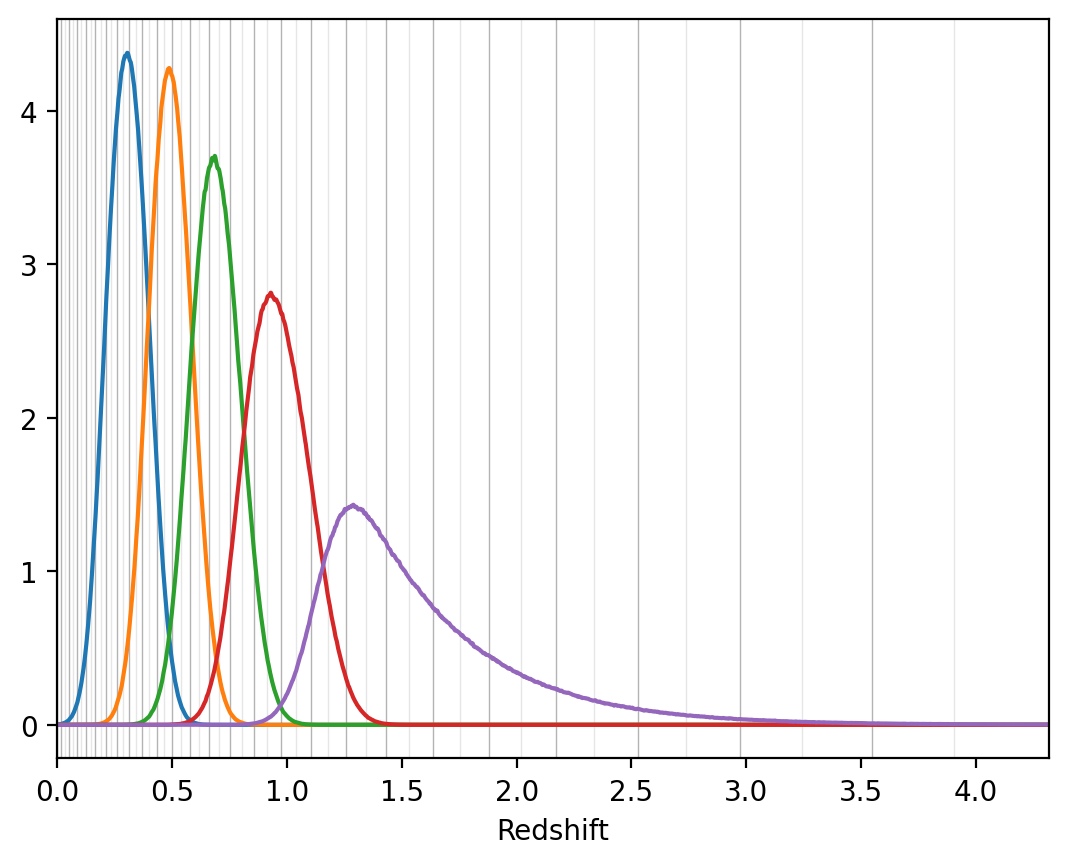

In [6]:
# Redshift distributions used for lensing
for z, nz in p.nzs:
    plt.plot(z, nz)
for z in p.shell_info['zsnapshot']:
    plt.axvline(z, c='.9', lw=.5, zorder=-1)
for z in p.shell_info['zmin']:
    plt.axvline(z, c='.7', lw=.5, zorder=-1)
plt.xlim(0,p.shell_info['zmax'][-1])
plt.xlabel('Redshift')

## Plot maps
Maps are saved in [HealSparse](https://github.com/LSSTDESC/healsparse) format, see https://healsparse.readthedocs.io/ for map handling.

Two useful things to know is that the healpix version of a HealSparse map `hsp` can be accessed as `hsp[:]` or `hsp.generate_healpix_map()`, and that they are saved in `"NESTED"` order (so use `nestTrue` in healpy functions).

In [7]:
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap

import skyproj
import healsparse
import healpy as hp

def cool_plot(hsp, count=False, catalog=False):
    fig = plt.figure(figsize=(6,6))
    ax = fig.add_subplot(111)
    
    lon_0 = 45.
    lat_0 = 45.
    delta = 30.
    sp = skyproj.HammerSkyproj(ax=ax, lon_0=lon_0, lat_0=lat_0)
    
    if count:
        hsp_log = healsparse.HealSparseMap.make_empty(hsp.nside_coverage, hsp.nside_sparse, dtype=hsp.dtype)
        hsp_log.update_values_pix(hsp.valid_pixels, np.arcsinh(hsp.get_values_pix(hsp.valid_pixels)))
        hsp = hsp_log
        colors = ["w", "#043987", "orange", "0.95"]
        nodes = [0.0, 0.65, 0.9, 1.0]
        cmap = LinearSegmentedColormap.from_list("mycmap", list(zip(nodes, colors)))

    else:
        cmap = mpl.cm.RdYlBu_r
        
    if catalog:
        sp.draw_hpxbin(hsp[1].data['ra'], hsp[1].data['dec'])
    else:
        _ = sp.draw_hspmap(hsp, cmap=cmap)
    
    sp.set_extent([lon_0-delta/2., lat_0+delta/2., lon_0-delta/2., lat_0+delta/2.])
    sp.set_xlabel('RA', fontsize='medium')
    sp.set_ylabel('DEC', fontsize='medium')

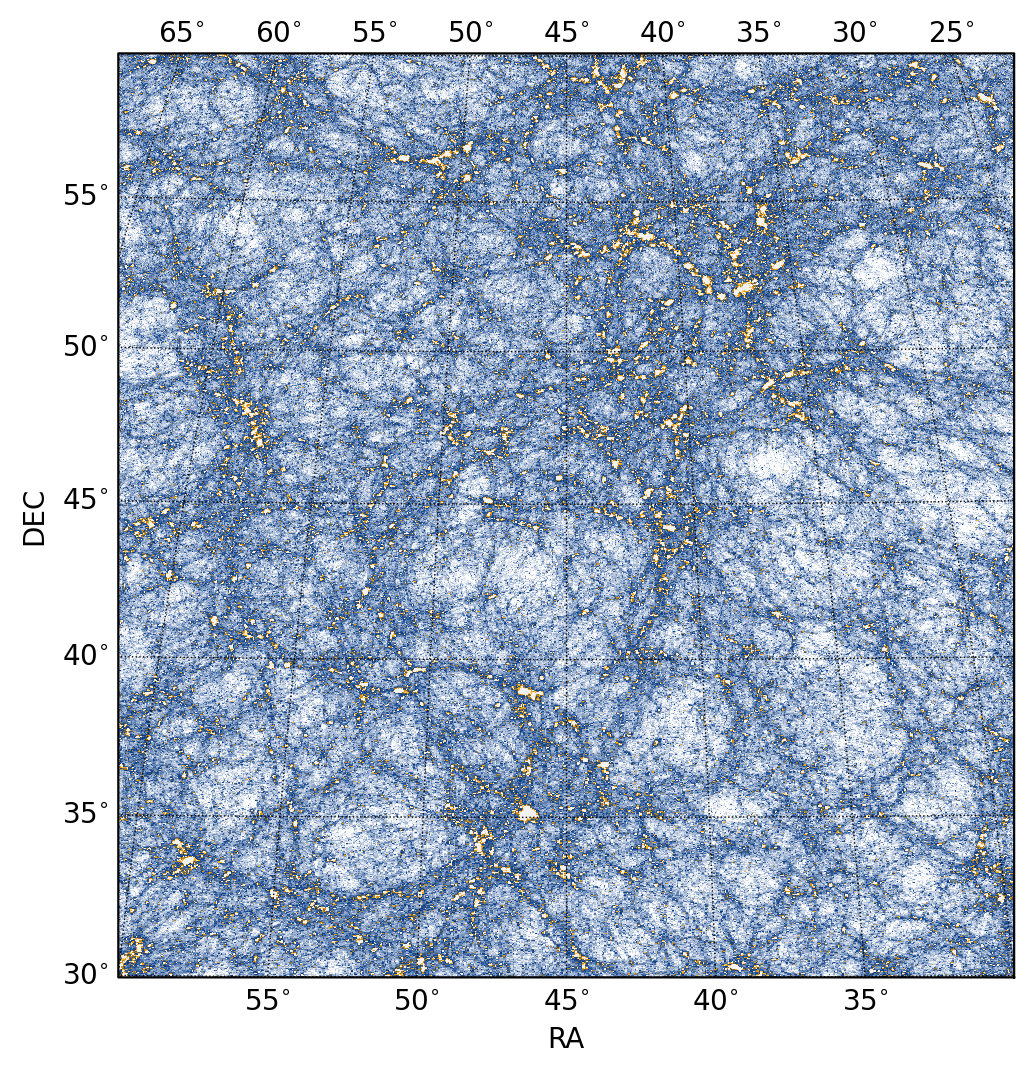

In [8]:
# Particle count map
hsp = p.load_shell(6)
cool_plot(hsp, count=True)

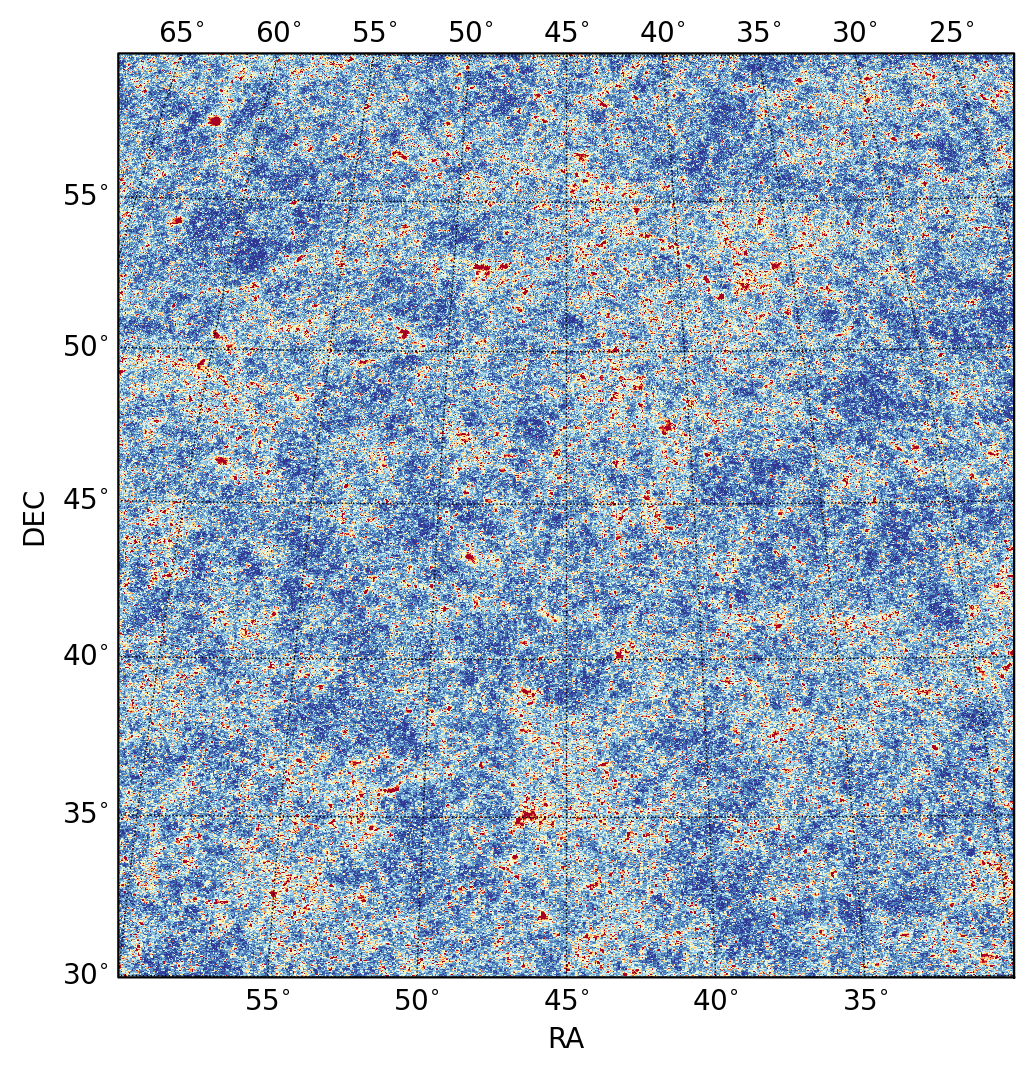

In [9]:
# Convergence maps
hsp = p.load_kappa(2)
cool_plot(hsp)

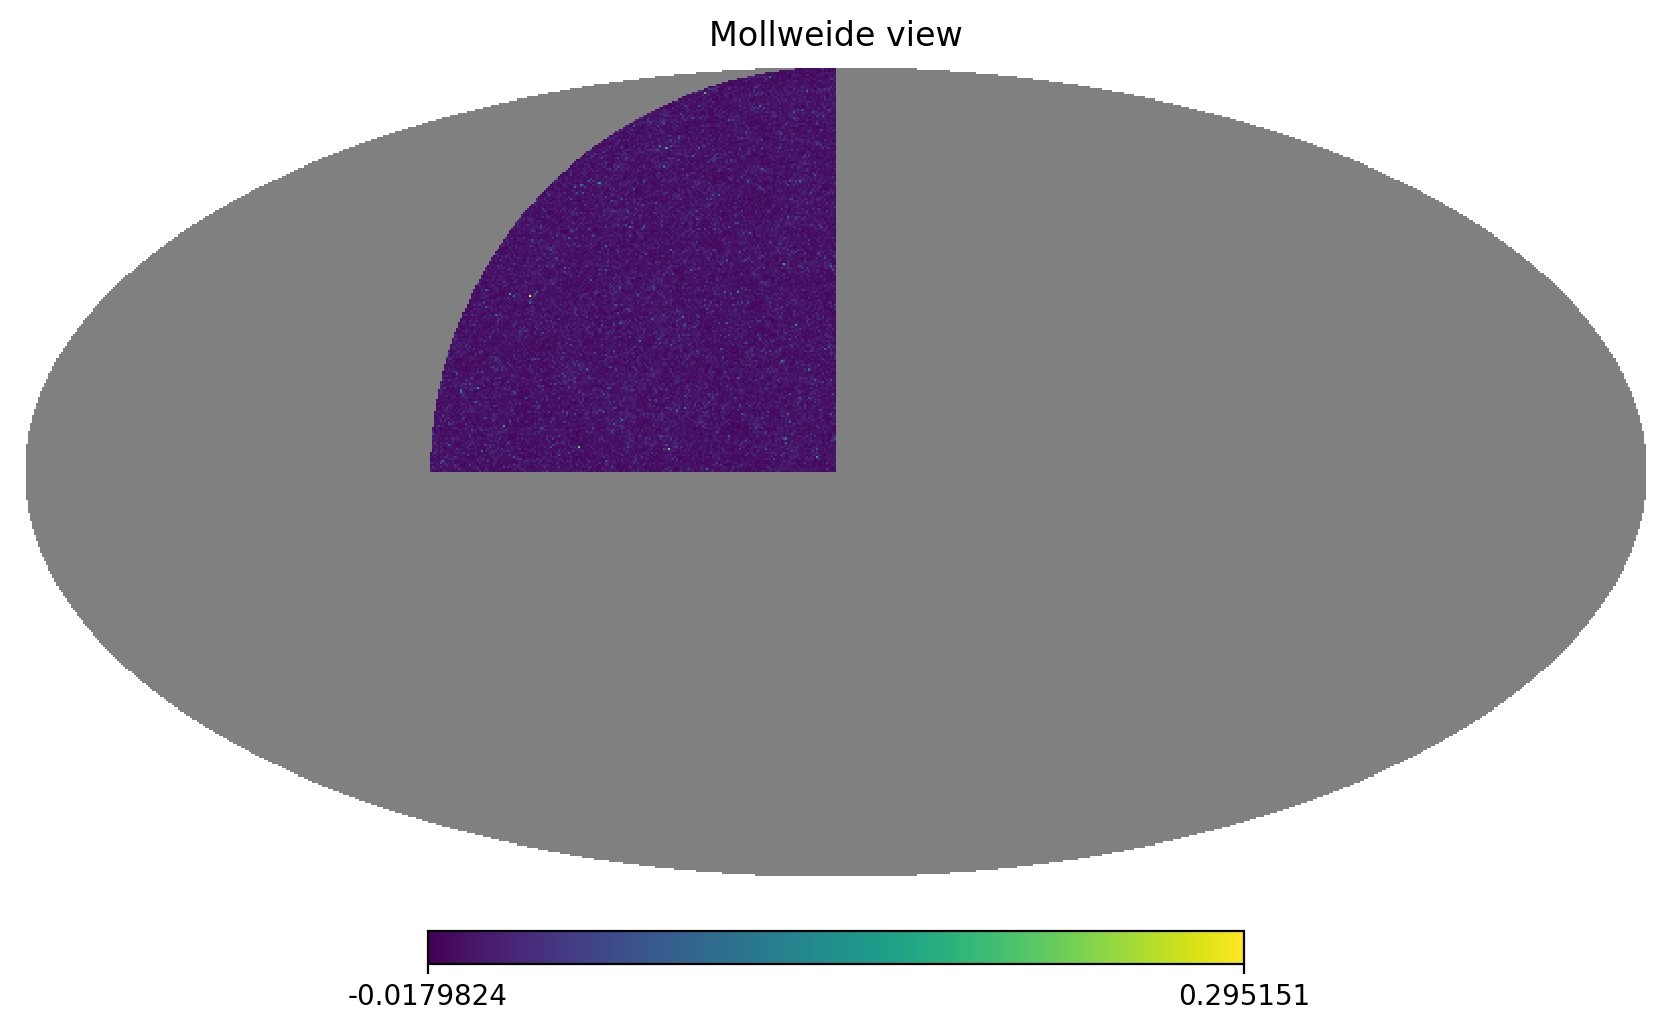

In [10]:
hp.mollview(hsp.generate_healpix_map(), nest=True)

## Catalogs
Catalogs are saved as fits files (one per shell or tomographic bin). Formats differ slight between halo catalogs and galaxy catalogs, but are pretty straightforward.

### Source galaxy catalogs

In [11]:
# Load a source galaxy catalog for a given tomographic bin
cat = p.load_catalog(3)

# The header contain information such as the density and biases of galaxies
cat[1].header

XTENSION= 'BINTABLE'           / binary table extension                         
BITPIX  =                    8 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                   40 / length of dimension 1                          
NAXIS2  =              1859800 / length of dimension 2                          
PCOUNT  =                    0 / number of group parameters                     
GCOUNT  =                    1 / number of groups                               
TFIELDS =                   10 / number of table fields                         
NBAR_0  =                  0.1                                                  
NBAR_1  =                  0.1                                                  
NBAR_2  =                  0.1                                                  
NBAR_3  =                  0.1                                                  
NBAR_4  =                  0

(0.0, 3.0)

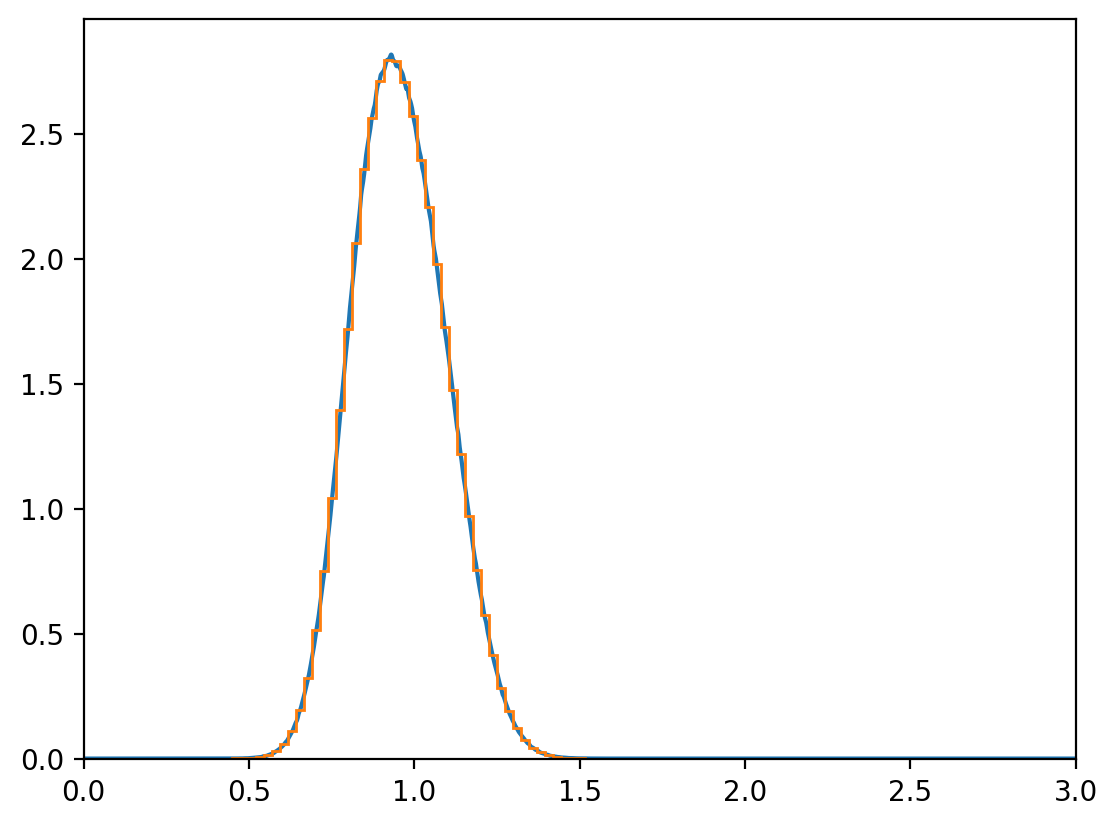

In [12]:
# Redshift distribution of the galaxy catalog matches the input distribution! \o/
plt.plot(p.nzs[3][0], p.nzs[3][1])
plt.hist(cat[1].data['z'], bins=50, density=True, histtype='step');
plt.xlim(0,3)

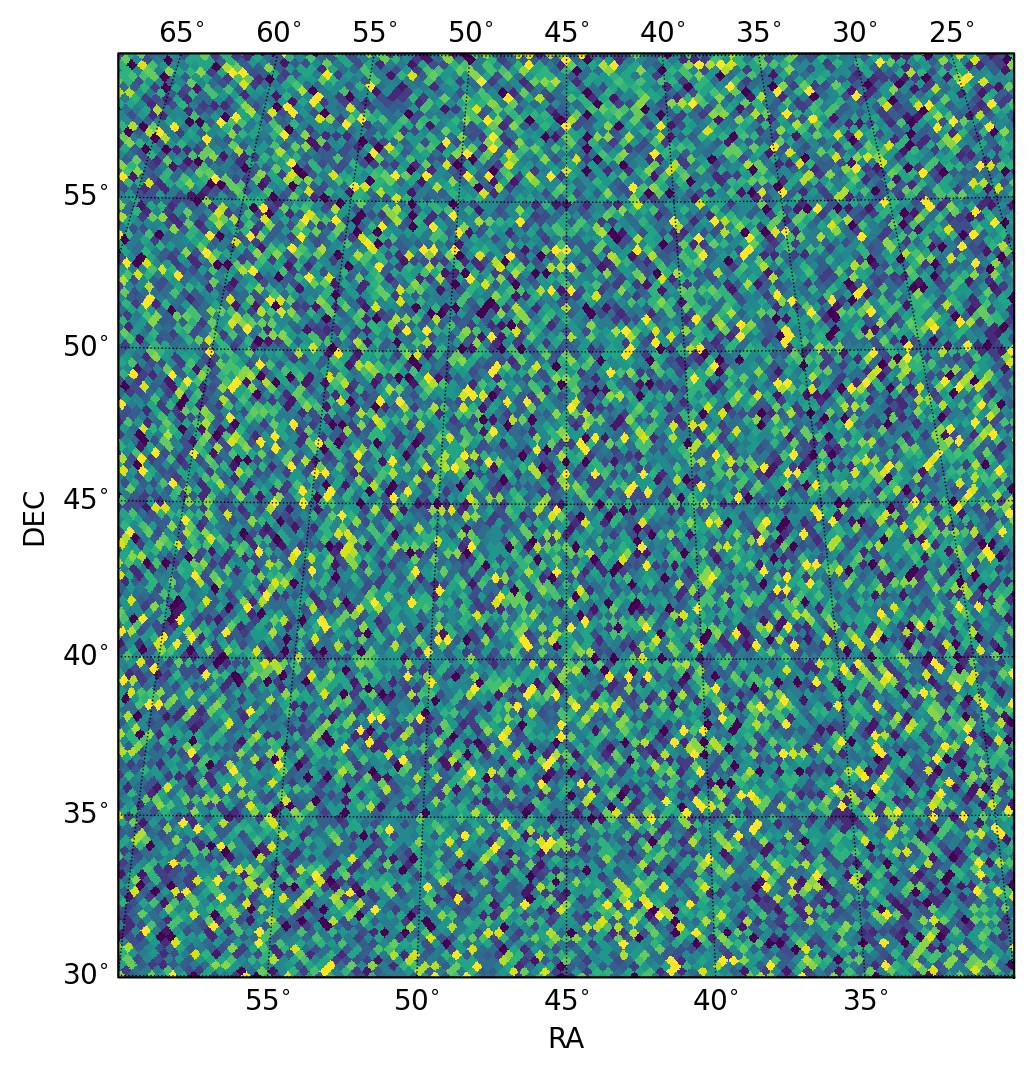

In [13]:
# We can do a bin plot of the positions of galaxies
cool_plot(cat, catalog=True)

### Halo catalogs

In [14]:
# Load halo catalog
haloes = p.load_haloes(0)

Text(0.5, 0, 'SOD mass [$M_\\odot/h$]')

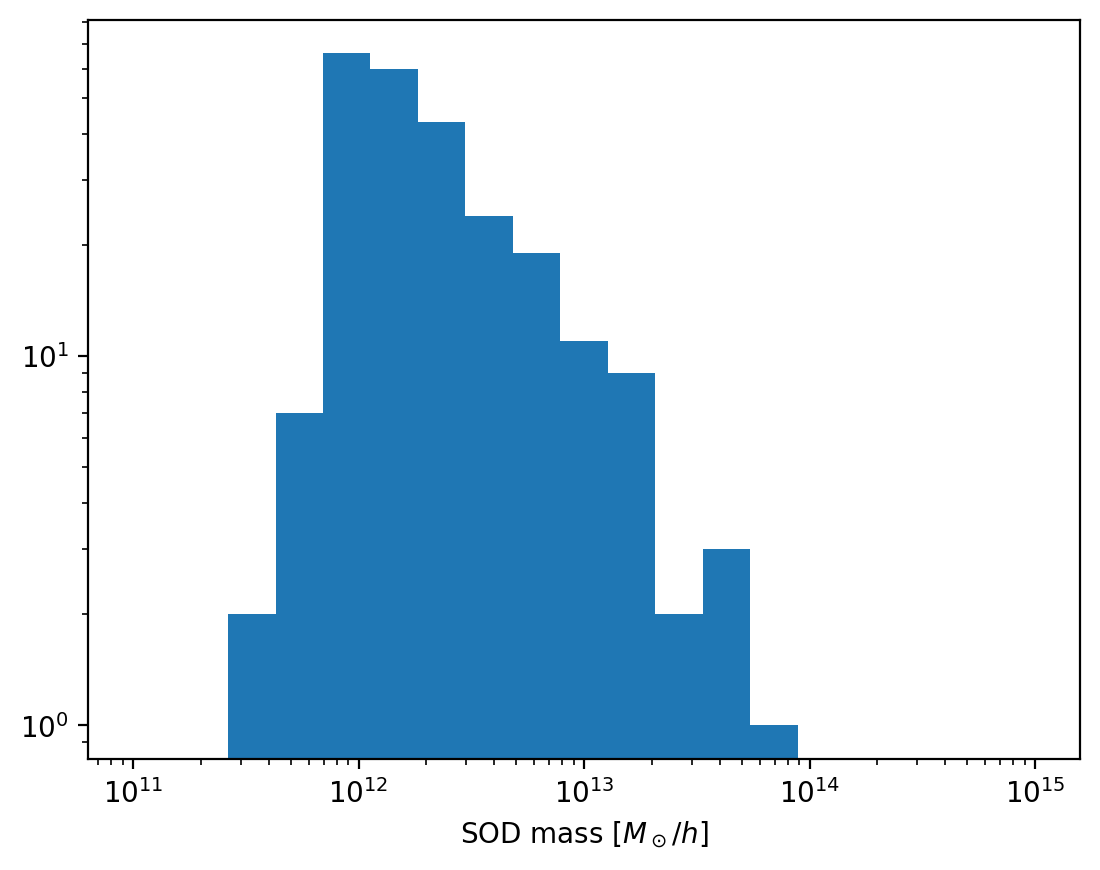

In [24]:
# Plot the halo mass function in that bin (using spherical overdensity masses from HACC)
plt.hist(haloes['sod_halo_mass'], bins=np.geomspace(1e11, 1e15, 20), log=True);
plt.xscale('log')
plt.xlabel('SOD mass [$M_\odot/h$]')